<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EC%9D%B4%EC%83%81%EA%B1%B0%EB%9E%98%ED%83%90%EC%A7%80_lsolation_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# 한글 표시하기
!apt-get install -y fonts-nanum
!rm ~/.cache/matplotlib -rf


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (8,164 kB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


In [2]:
import matplotlib.pyplot as plt

plt.rc('font', family='NanumBarunGothic')
mpl.rc('axes', unicode_minus = False)


In [3]:
import numpy as np
import pandas as pd

In [4]:
np.random.seed(42)
# 정상 거래
n_normal=1000
# 사기 거래(전체 약 5%)
# 실제로는 사기 거래가 전체 0.01~0.1% 수준임
n_fraud=50

In [19]:
# 정상 거래 패턴
normal=pd.DataFrame({
    'amount':np.random.normal(50000,20000,n_normal).clip(10),
    'hour':np.random.choice(range(8,22),n_normal),
    'transaction_count_1h':np.random.randint(1,4,n_normal),
    'location_risk_score':np.random.uniform(0,0.3,n_normal),
    'time_since_last_tx':np.random.normal(120,60,n_normal).clip(10),
    'is_fraud':0
})

In [20]:
# 사기거래 패턴(이상치 의도적 주입)
fraud=pd.DataFrame({
    'amount':np.random.normal(800000,200000,n_fraud).clip(100000),
    'hour':np.random.choice([2,3,4,23],n_fraud),
    'transaction_count_1h':np.random.randint(8,20,n_fraud),
    'location_risk_score':np.random.uniform(0.7,1.0,n_fraud),
    'time_since_last_tx':np.random.normal(3,2,n_fraud).clip(0.5),
    'is_fraud':1
})

In [21]:
df=pd.concat([normal,fraud]).reset_index(drop=True)

### 표준화
각 특성이 동등하게 모델 판단에 기여할 수 있도록 표준화 진행합니다.

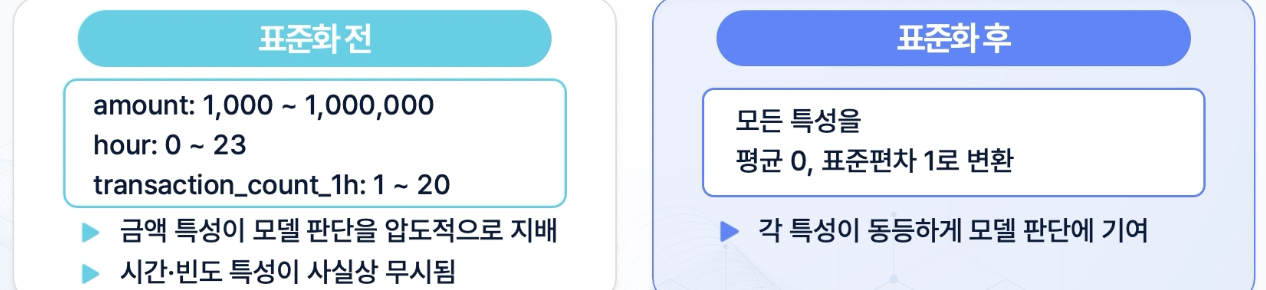

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

features=['amount','transaction_count_1h','location_risk_score','time_since_last_tx']

scaler=StandardScaler()

X=scaler.fit_transform(df[features])

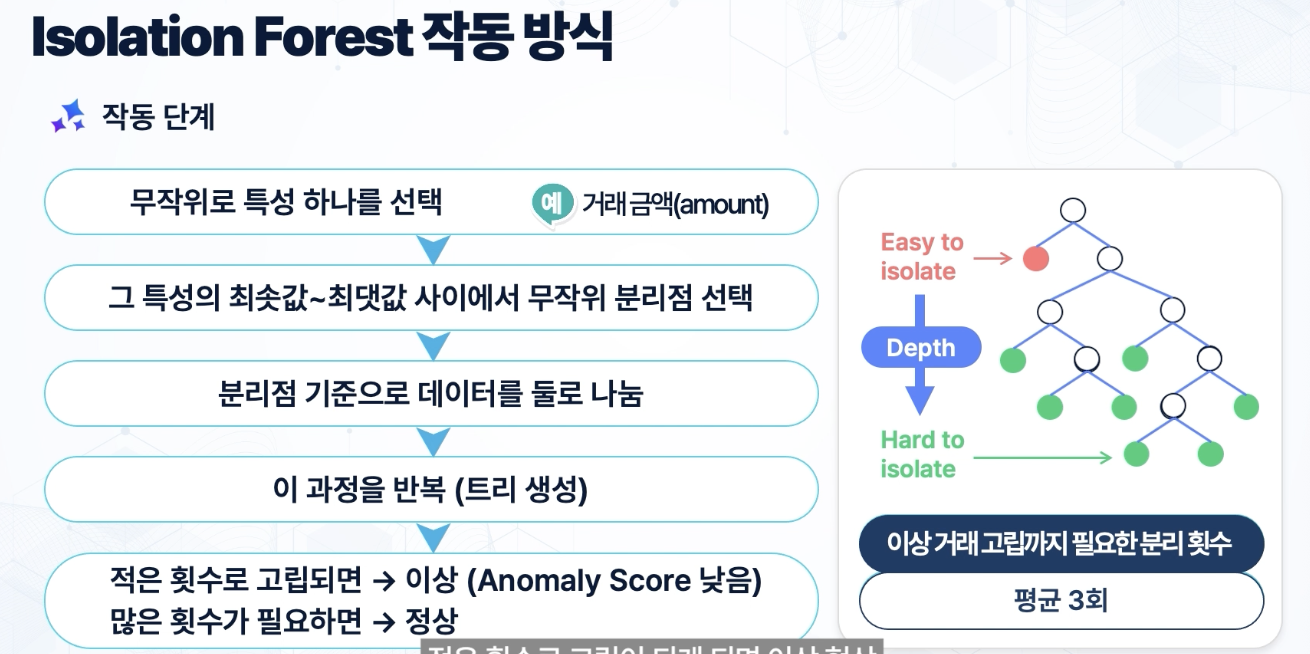

- 사기 레이블(정답)없이 학습
- 정상 거래 1,000건의 패턴만으로 "이 패턴과 얼마나 다른가"를 측정
- 새로운 사기 패턴이 등장해도 "군집에서 멀리 떨어져 있으면" 탐지 가능

In [23]:
model=IsolationForest(
    n_estimators=100, # 트리 개수
    contamination=0.05, # 전체 데이터 중 이상치 비율 추정
    random_state=42

)

model.fit(X)

# 이상치 점수: 낮을수록 이상(-1~0 범위)
df['anomaly_score']=model.decision_function(X)

# 예측: -1=이상, 1=정상
df['predicted']=model.predict(X)
df['predicted_fraud']=(df['predicted']==-1).astype(int)

In [24]:
print(df['is_fraud'].value_counts())
print(df['predicted_fraud'].value_counts())

is_fraud
0    1000
1      50
Name: count, dtype: int64
predicted_fraud
0    997
1     53
Name: count, dtype: int64


이상 점수 분포 시각화

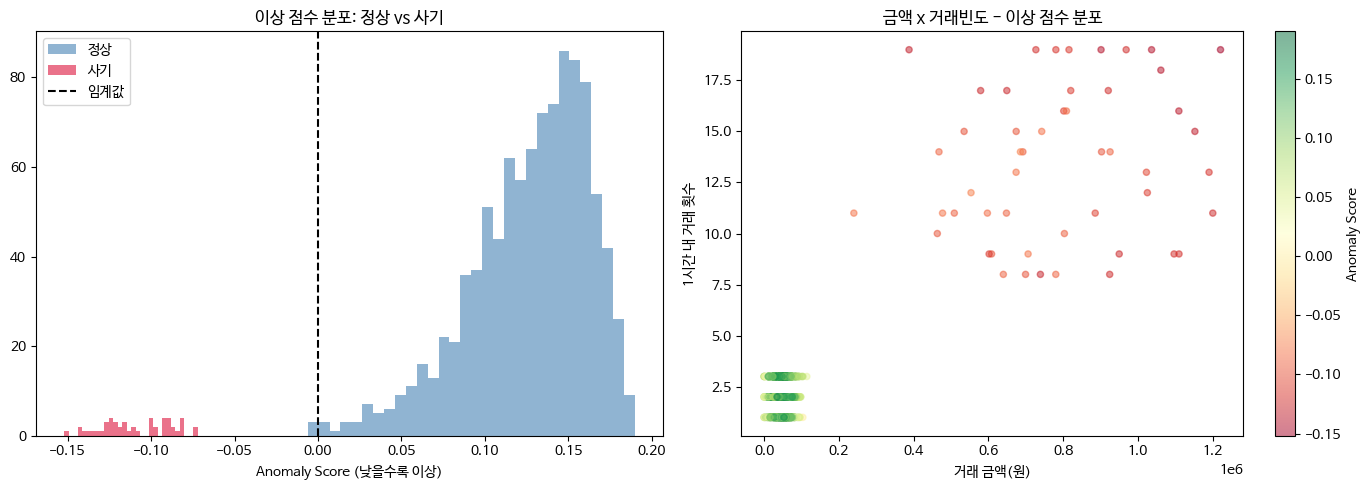

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# [차트1] 이상 점수 분포 히스토그램
for label, color, name in [
    (0, 'steelblue', '정상'),
    (1, 'crimson', '사기')
]:
    subset = df[df['is_fraud'] == label]['anomaly_score']

    axes[0].hist(
        subset,
        bins=30,
        alpha=0.6,
        color=color,
        label=name
    )

axes[0].axvline(
    x=df['anomaly_score'].quantile(0.05),
    color='black',
    linestyle='--',
    label='임계값'
)

axes[0].set_title('이상 점수 분포: 정상 vs 사기')
axes[0].set_xlabel('Anomaly Score (낮을수록 이상)')
axes[0].legend()


# [차트2] 금액 x 거래빈도
scatter = axes[1].scatter(
    df['amount'],
    df['transaction_count_1h'],
    c=df['anomaly_score'],
    cmap='RdYlGn',
    alpha=0.5,
    s=20
)

plt.colorbar(
    scatter,
    ax=axes[1],
    label='Anomaly Score'
)

axes[1].set_title('금액 x 거래빈도 - 이상 점수 분포')
axes[1].set_xlabel('거래 금액(원)')
axes[1].set_ylabel('1시간 내 거래 횟수')

plt.tight_layout()
plt.show()

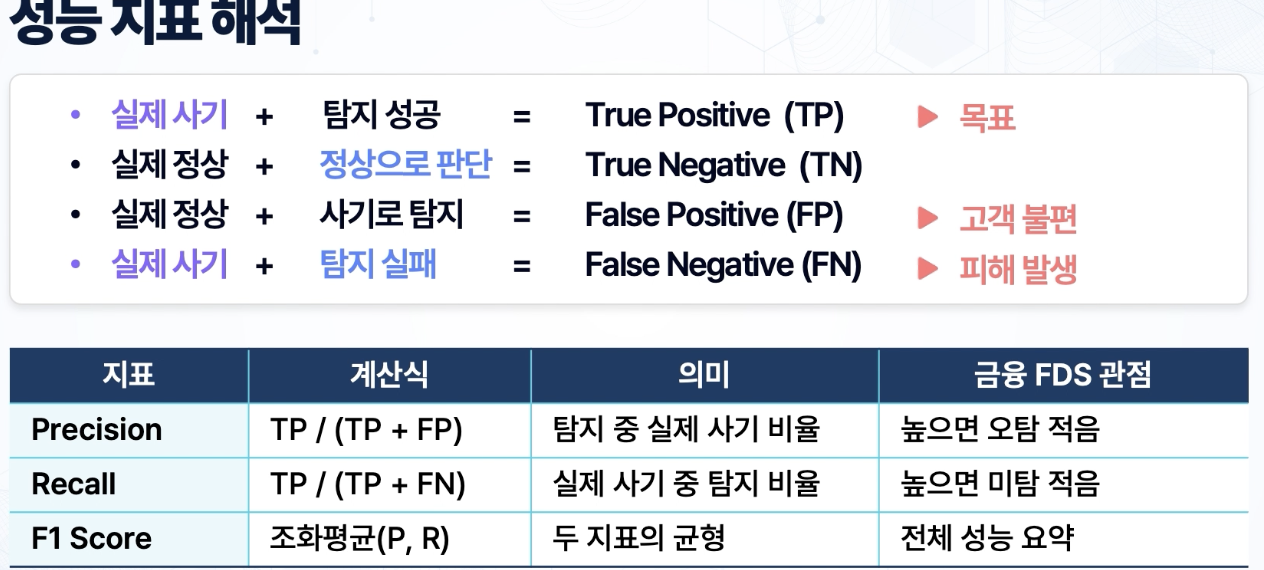

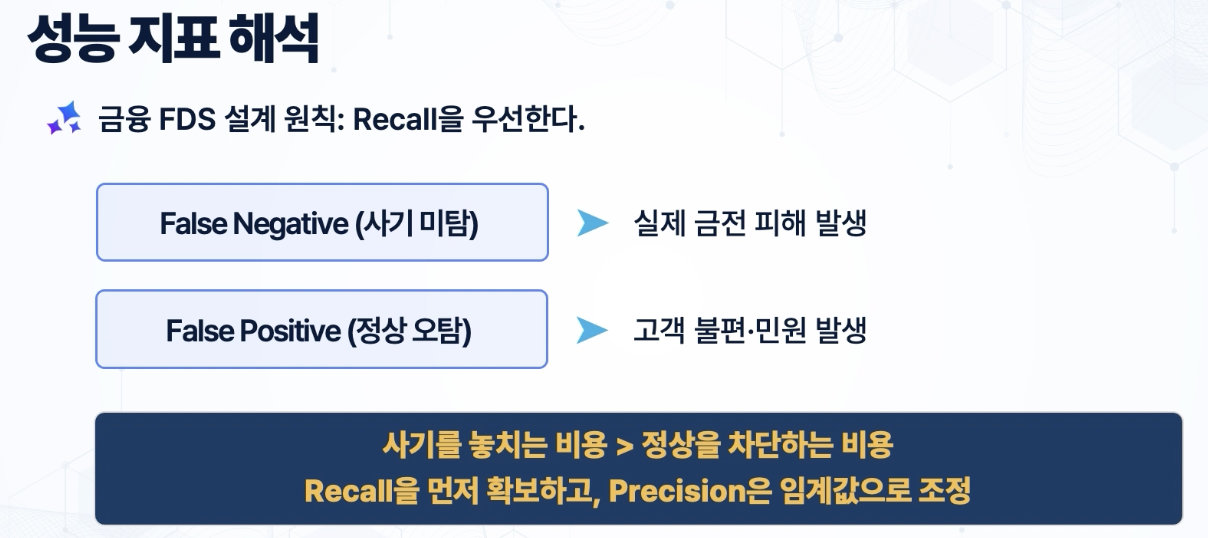

              precision    recall  f1-score   support

          정상       1.00      1.00      1.00      1000
          사기       0.94      1.00      0.97        50

    accuracy                           1.00      1050
   macro avg       0.97      1.00      0.98      1050
weighted avg       1.00      1.00      1.00      1050



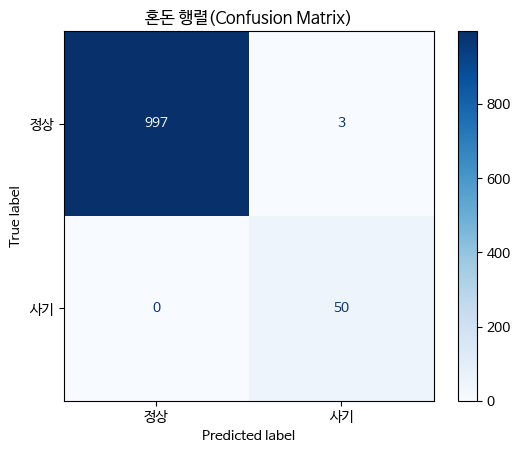

In [29]:
from sklearn.metrics import (classification_report,confusion_matrix,ConfusionMatrixDisplay)

# 성능 리포트
print(classification_report(
    df['is_fraud'],
    df['predicted_fraud'],
    target_names=['정상','사기']
))

# Confusion Matrix 시각화
cm=confusion_matrix(df['is_fraud'],
                    df['predicted_fraud'])
disp=ConfusionMatrixDisplay(confusion_matrix=cm,
                            display_labels=['정상','사기'])
disp.plot(cmap='Blues')
plt.title('혼돈 행렬(Confusion Matrix)')
plt.show()

- IsolationForest는 정답(레이블)이 없이 학습합니다.
정상 패턴이 군집에서 얼마나 멀리 떨어져 있는가로 이상을 판단합니다.
- Recall을 먼저 확보하고, Precision은 임계값으로 조정합니다.
사기를 놓치는 비용이 정상을 차단하는 비용보다 큽니다.


실제 데이터를 적용할 경우에는

- IsolationForest의 contamination 파라미터를 조정합니다. class 불균형을 보완하는 방법에 대한 고민도 필요합니다.

- AI 기반의 탐지 알고리즘은 보조적인 수단으로 사용합니다. 최종 결정은 내부 전문가의 판단 프로세스를 거쳐야 합니다.